# Mixed neural clocks, SIMD sweeps, and Balloon–Windkessel BOLD

This small, deterministic regional example combines two genuinely different
neural update rates with five different parameter rows, batched four lanes at
a time, and both global and local Balloon–Windkessel (BW) monitors. It needs
no downloaded connectivity. BW here is **fractional BOLD change**, not the
HRF convolution selected by the legacy `monitor="bold"` API.

**Setup:** use a compatible development checkout or native wheel containing
the C++ hybrid BW sweep API. Ordinary released PyPI packages may predate it.
From the root of this `tvbkh` checkout, for example (Python 3.12 or newer):

```bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install ./tvb_library matplotlib jupyter ipykernel
python -m ipykernel install --user --name tvb-cpp-demo --display-name "TVB C++ demo"
jupyter notebook tvb_documentation/demos/cpp_hybrid_multirate_bw_sweep.ipynb
```

Choose the **TVB C++ demo** kernel in Jupyter. A source build needs a working
C++ compiler and build tools; see the checkout's
[C++ build instructions](https://github.com/the-virtual-brain/tvb-root/blob/tvbkh/tvb_library/tvb/simulator/backend/cpp_hybrid/README.md).
Alternatively,
install a compatible wheel built for this API and your machine in that same
environment instead of `./tvb_library`. The check below fails with setup
guidance if the compiled extension or BW sweep API is missing; there is no
fallback. Run all cells in order.



In [1]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

try:
    from tvb.simulator import integrators
    from tvb.simulator.backend.cpp_hybrid import notebook as hybrid_notebook
    from tvb.simulator.backend.cpp_hybrid.backend import CppHybridBackend
    from tvb.simulator.hybrid import NetworkSet, Subnetwork
    from tvb.simulator.models.linear import Linear
    from tvb.simulator.monitors import BalloonWindkessel, Raw
except ImportError as exc:
    raise ImportError("Install a compatible TVB development build with its native "
                      "C++ extension in this notebook's kernel; see Setup above.") from exc
if ("bw" not in inspect.signature(hybrid_notebook.sweep).parameters or
        "bw" not in inspect.signature(CppHybridBackend.sweep).parameters):
    raise RuntimeError("This TVB installation lacks BW sweep support. Install a "
                       "compatible development checkout or native wheel; see Setup above.")

MASTER_DT = 2.5  # ms
SLOW_DT = 5.0  # ms, two master ticks
DURATION = 40_000.0  # ms = 40 s
GAMMAS = np.array([-0.0001, -0.0002, -0.0003, -0.0004, -0.0005], dtype=np.float32)
INITIAL = [np.ones((1, 2, 1)), np.ones((1, 2, 1))]


def network(fast_gamma):
    """Two independent, explicitly mapped regional subnetworks."""
    fast = Subnetwork(name="fast", nnodes=2, node_indices=np.array([0, 1]),
                      model=Linear(gamma=np.array([float(fast_gamma)])),
                      scheme=integrators.EulerDeterministic(dt=MASTER_DT))
    slow = Subnetwork(name="slow", nnodes=2, node_indices=np.array([2, 3]),
                      model=Linear(gamma=np.array([-0.0002])),
                      scheme=integrators.EulerDeterministic(dt=SLOW_DT))
    return NetworkSet(subnets=[fast, slow]).configure()


def bw(period):
    return BalloonWindkessel(period=period, variables_of_interest=np.array([0]),
                             drive_baseline=0.0, drive_scale=0.5)


def initials():
    return [x.copy() for x in INITIAL]




/Users/duke/src/tvb-docs-safe.param-sleep/.venv/lib/python3.12/site-packages/tvb/simulator/hybrid/__init__.py:165: UserWarning: Hybrid simulation is experimental: please report bugs or suggestions.
  warnings.warn(msg)
/Users/duke/src/tvb-docs-safe.param-sleep/.venv/lib/python3.12/site-packages/tvb/datatypes/surfaces.py:60: UserWarning: Geodesic distance module is unavailable; some functionality for surfaces will be unavailable.
  warnings.warn(msg)


## Model, clocks and calibration

Each uncoupled region follows `dx/dt = gamma*x`, with negative gamma in
inverse milliseconds. The initial condition `x=1` is a deliberate non-rest
perturbation, not an applied stimulus; `x=0` is its resting baseline. Euler
integration with these small negative rates is stable and relaxes over a few
to ten seconds. These are illustrative model units, not an anatomical model.

The master ticks every 2.5 ms. The fast source updates each tick and the slow
source every second tick (5 ms). Global BW gathers observations on the master
clock, holding a slow source's latest observation between updates. A local BW
samples its own source updates. Therefore global and slow-local BW are not
universally equal when their sampling differs; we do not assert that parity.

BW averages observations over each complete 10 ms drive window and maps the
mean to `(mean - 0) * 0.5` s⁻². The zero baseline and scale are explicit,
illustrative calibration choices, **not** empirical neurovascular fits.
The nominal shared hemodynamic parameters are not population estimates; the
output is a model demonstration, not a physiological prediction. The solver
holds each drive for two 5 ms RK4 steps.

Below, source-local Raw streams show actual post-update timestamps. The slow
staircase is reconstructed on the master grid with zero-order hold and the
known initial condition; it is not a heterogeneous global Raw monitor.



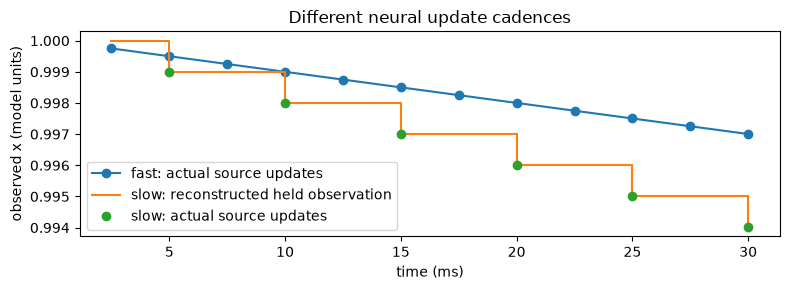

In [2]:
backend = CppHybridBackend()
_, local_raw = backend.run_network(
    network(GAMMAS[0]), 12, initial_states=initials(),
    subnet_monitors={"fast": [Raw()], "slow": [Raw()]})
fast_t, fast_raw = local_raw["fast"][0]
slow_t, slow_raw = local_raw["slow"][0]
np.testing.assert_array_equal(fast_t, MASTER_DT * np.arange(1, 13))
np.testing.assert_array_equal(slow_t, SLOW_DT * np.arange(1, 7))
fast_trace = fast_raw[:, 0, 0, 0]
slow_trace = slow_raw[:, 0, 0, 0]
assert np.all(np.diff(fast_trace) < 0) and np.all(np.diff(slow_trace) < 0)
held = np.r_[1.0, slow_trace][np.searchsorted(slow_t, fast_t, side="right")]
assert np.all(held[::2] == np.r_[1.0, slow_trace[:-1]])
assert np.all(held[1::2] == slow_trace)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(fast_t, fast_trace, "o-", label="fast: actual source updates")
ax.step(fast_t, held, where="post", label="slow: reconstructed held observation")
ax.plot(slow_t, slow_trace, "o", label="slow: actual source updates")
ax.set(xlabel="time (ms)", ylabel="observed x (model units)", title="Different neural update cadences")
ax.legend(); fig.tight_layout(); plt.show()



## A five-row SIMD sweep

`fast.gamma` is a neural parameter; geometry, clocks and BW calibration do
not vary. The rows below are paired in the displayed order. For several axes,
`grid=False` pairs equal-length arrays; `grid=True` makes a Cartesian product
with the last parameter varying fastest. Width is lanes per batch, whereas
workers are threads running batches: with width 4, five real rows require two
batches and the last batch is padded with a valid row. Padding is discarded
from the returned results; it is not an extra scientific experiment.

The global result uses canonical node order `[fast 0, fast 1, slow 0, slow 1]`;
local output uses fast-source order. Each placement has its own grid in ms.
BW data axes are `(sweep, time, 1 VOI, node, 1 mode)`, float32; times are
float64. These points are means over *complete output periods*, labelled at
their midpoints, not instantaneous samples. No incomplete tail is flushed.



In [3]:
def sweep(nstep):
    return hybrid_notebook.sweep(
        network(GAMMAS[0]), nstep=nstep, width=4, workers=2,
        monitor="none", initial_states=initials(),
        bw={"global": bw(1000.0), "local": {"fast": bw(2000.0)}},
        **{"fast.gamma": GAMMAS})


result = sweep(int(DURATION / MASTER_DT))
global_t, global_y = result.bw_global
local_t, local_y = result.bw_local["fast"]
np.testing.assert_array_equal(result.sweep_values[:, 0], GAMMAS)
np.testing.assert_array_equal(global_t, np.arange(40) * 1000.0 + 500.0)
np.testing.assert_array_equal(local_t, np.arange(20) * 2000.0 + 1000.0)
assert global_t.dtype == local_t.dtype == np.float64
assert global_y.dtype == local_y.dtype == np.float32
assert global_y.shape == (5, 40, 1, 4, 1)
assert local_y.shape == (5, 20, 1, 2, 1)
assert np.isfinite(global_y).all() and np.isfinite(local_y).all()
assert np.max(np.abs(global_y)) > 1e-6 and np.max(np.abs(local_y)) > 1e-6
assert np.max(np.abs(global_y[0, :, 0, 0, 0] - global_y[-1, :, 0, 0, 0])) > 1e-6
# Slow geometry and dynamics are unchanged across all five real rows.
for row in range(1, len(GAMMAS)):
    np.testing.assert_array_equal(global_y[row, :, :, 2:, :], global_y[0, :, :, 2:, :])
print("rows / gamma [1/ms]:", result.sweep_values[:, 0])
print("global (ms, shape):", global_t[[0, -1]], global_y.shape)
print("local fast (ms, shape):", local_t[[0, -1]], local_y.shape)



rows / gamma [1/ms]: [-0.0001 -0.0002 -0.0003 -0.0004 -0.0005]
global (ms, shape): [  500. 39500.] (5, 40, 1, 4, 1)
local fast (ms, shape): [ 1000. 39000.] (5, 20, 1, 2, 1)


## Independent scalar controls and incomplete tails

Rebuild the network for the first and last parameters and use the public
scalar `run_network` path, rather than another sweep lane. Compare each BW
placement on its own grid with the same precision envelope used in the
installed-native sweep tests. A separate 2.5 s run has two complete global
periods and one local period: its remaining partial periods are not emitted.



In [4]:
for row in (0, len(GAMMAS) - 1):
    outputs, local = backend.run_network(
        network(GAMMAS[row]), int(DURATION / MASTER_DT), initial_states=initials(),
        monitors=[bw(1000.0)], subnet_monitors={"fast": [bw(2000.0)]})
    for (times, data), expected in ((result.bw_global, outputs[0][0]),
                                    (result.bw_local["fast"], local["fast"][0])):
        np.testing.assert_array_equal(times, expected[0])
        np.testing.assert_allclose(data[row], expected[1], rtol=1e-6, atol=1e-10)

tail = sweep(1000)  # 2500 ms
np.testing.assert_array_equal(tail.bw_global[0], [500.0, 1500.0])
np.testing.assert_array_equal(tail.bw_local["fast"][0], [1000.0])
np.testing.assert_allclose(tail.bw_global[1], global_y[:, :2], rtol=1e-6, atol=1e-10)
np.testing.assert_allclose(tail.bw_local["fast"][1], local_y[:, :1], rtol=1e-6, atol=1e-10)
print("Scalar controls and complete-period tail checks passed.")



Scalar controls and complete-period tail checks passed.


## Plot the response

Forty seconds captures both the hemodynamic rise and the decay of the bounded
neural perturbations. Values below remain **fractional** ΔS/S; multiply by
100 only if labelling the result percent. The fast region varies with gamma,
while the fixed slow region is a useful lane-independence control.



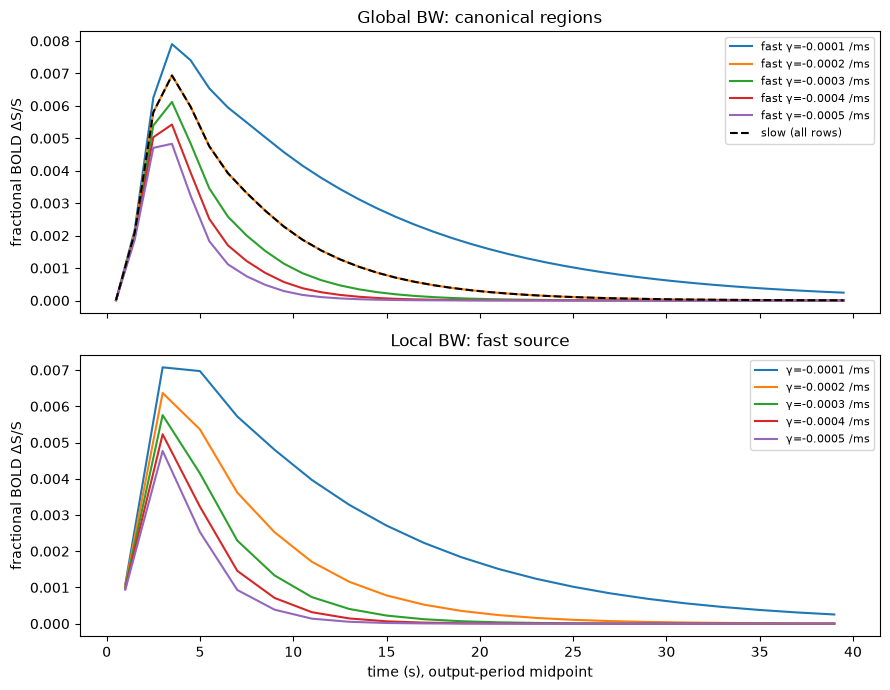

In [5]:
fig, (ax_global, ax_local) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for row, gamma in enumerate(GAMMAS):
    ax_global.plot(global_t / 1000, global_y[row, :, 0, 0, 0],
                   label=f"fast γ={gamma:.4g} /ms")
    ax_local.plot(local_t / 1000, local_y[row, :, 0, 0, 0],
                  label=f"γ={gamma:.4g} /ms")
ax_global.plot(global_t / 1000, global_y[0, :, 0, 2, 0], "k--", label="slow (all rows)")
ax_global.set(title="Global BW: canonical regions", ylabel="fractional BOLD ΔS/S")
ax_local.set(title="Local BW: fast source", xlabel="time (s), output-period midpoint",
             ylabel="fractional BOLD ΔS/S")
ax_global.legend(fontsize=8); ax_local.legend(fontsize=8)
fig.tight_layout(); plt.show()
